#Modelo de segmentación

El objetivo de este modelo es poder determinar perfiles musicales, con el fin de poder generar listas de reproducción de forma automática por similitud musical, mejorando también las recomendaciones a los usuarios en base al historial de reproducción de estos.

##Librerías a utilizar

In [ ]:
!pip install --upgrade jupyter_client

In [ ]:
!pip install kneed

In [ ]:
import requests
import hashlib
import io

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import FunctionTransformer, RobustScaler, StandardScaler, OneHotEncoder, MinMaxScaler
from mlxtend.frequent_patterns import apriori, association_rules

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from kneed import KneeLocator

##Carga del dataset

In [ ]:
url = "https://raw.githubusercontent.com/Mapabaoy12/EncargoMachineLearning2/refs/heads/main/dataML/Spotify_Tracks_Dataset.csv"
HASH_ORIGINAL = "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd"

In [ ]:
try:
    # intento de descarga y validación
    response = requests.get(url)
    response.raise_for_status()  # verifica que url funcione y no de error

    contenido_raw = response.content
    hash_calculado = hashlib.sha256(contenido_raw).hexdigest()

    if hash_calculado == HASH_ORIGINAL:
        print("AUDITORÍA EXITOSA: Integridad de procedencia garantizada.")
        df = pd.read_csv(io.BytesIO(contenido_raw))
        print("Dataset cargado correctamente.")
    else:
        # si hash no coincide, da un error manual
        raise ValueError("El hash no coincide. El archivo ha sido modificado o está corrupto.")

except Exception as e:
    # captura cualquier error y detiene el proceso
    raise RuntimeError(f"FALLO CRÍTICO: No se pudo procesar el dataset. Detalle: {e}")

AUDITORÍA EXITOSA: Integridad de procedencia garantizada.
Dataset cargado correctamente.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

##Selección de columnas para segmentación

In [ ]:
# Depuración de registros nulos y filas redundantes
df_clean = df.dropna(subset=['track_id', 'artists', 'track_name', 'popularity']).copy()
# Resolución de duplicados a nivel de track único
df_clean = df_clean.groupby('track_id', as_index=False).first()
#Descarte de columnas
columnas_a_descartar = ['Unnamed: 0', 'track_id', 'key', 'track_name', 'album_name', 'artists', 'popularity', 'track_genre', 'duration_ms', 'mode', 'explicit','time_signature','duration_ms']
df_clean.drop(columns=columnas_a_descartar, errors='ignore', inplace=True)

Se seleccionan principalmente columnas numéricas asociadas al perfil sonoro de los tracks, ya que se alinea mejor con el objetivo principal de este modelo. Se utilizan las variables categóricas más adelante, para la generación de los perfiles.

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89740 entries, 0 to 89739
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      89740 non-null  float64
 1   energy            89740 non-null  float64
 2   loudness          89740 non-null  float64
 3   speechiness       89740 non-null  float64
 4   acousticness      89740 non-null  float64
 5   instrumentalness  89740 non-null  float64
 6   liveness          89740 non-null  float64
 7   valence           89740 non-null  float64
 8   tempo             89740 non-null  float64
dtypes: float64(9)
memory usage: 6.2 MB


In [ ]:
class DataFrameConverter(BaseEstimator, TransformerMixin):
  """
  Convierte un array en un DataFrame

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  feature_names_ : array-like
    Nombres de las columnas.
  Returns
  -------
  DataFrame
    Conjunto de datos con nombres de columnas.
  """
  def __init__(self, preprocessor):
    self.preprocessor = preprocessor
    self.feature_names_ = None

  def fit(self, X, y=None):
    # Obtener nombres después de fit del preprocessor
    self.feature_names_ = self.preprocessor.get_feature_names_out()
    return self

  def transform(self, X):
    return pd.DataFrame(X, columns=self.feature_names_)

##Definición de pipelines

In [ ]:
cols_num = ['danceability','energy','loudness','speechiness','acousticness','instrumentalness','liveness','tempo','valence']

In [ ]:
pipe_num = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", RobustScaler())
    ]
)

preprocesadorSE = ColumnTransformer(
    transformers=[
        ("num", pipe_num, cols_num)
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

Se utiliza RobustScaler debido a la gran cantidad de atípicos. Además, debido al sesgo en las distribuciones de las variables, se prefiere imputar posibles valores faltantes por la mediana, ya que es una métrica más robusta y que no sube el costo computacional.

In [ ]:
X = df_clean
X_scaled = preprocesadorSE.fit_transform(X)
inertias = []
silhouettes = []

for k in range(1, 11):

    modelo = KMeans(
        n_clusters=k,
        random_state=67,
        n_init=10
    )

    modelo.fit(X_scaled)
    inertias.append(modelo.inertia_)

    if k > 1:
        silhouettes.append(silhouette_score(X_scaled, modelo.labels_))
    else:
        silhouettes.append(0)

kl = KneeLocator(
    range(1, 11),
    inertias,
    curve='convex',
    direction='decreasing'
)

print("K óptimo:", kl.elbow)

K óptimo: 3


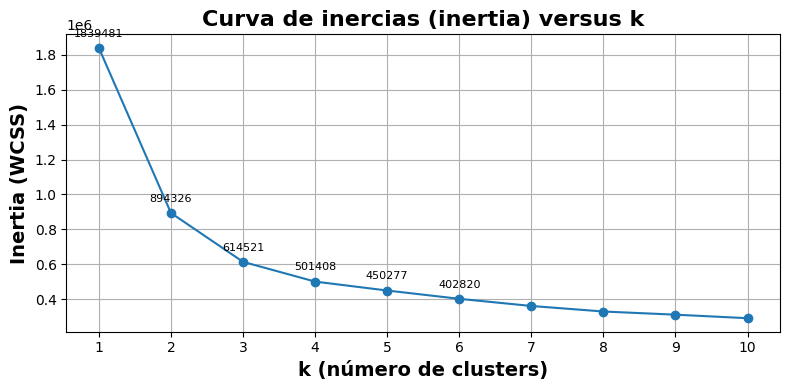

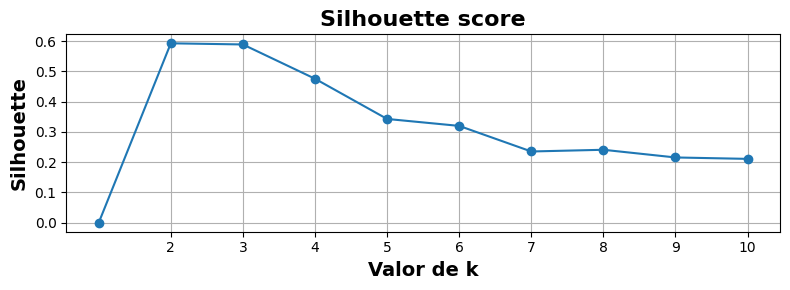

In [ ]:
range_k = range(1, 11)

plt.figure(figsize=(8,4))
plt.plot(list(range_k), inertias, marker='o')
plt.title("Curva de inercias (inertia) versus k", fontsize=16, fontweight="bold")
plt.xlabel("k (número de clusters)", fontsize=14, fontweight="bold")
plt.ylabel("Inertia (WCSS)", fontsize=14, fontweight="bold")
plt.xticks(list(range_k))

for k_val, val in zip(list(range_k), inertias):
    if k_val <= 6:
        plt.annotate(f"{val:.0f}", (k_val, val), textcoords="offset points", xytext=(0,8), ha='center', fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,3))
plt.plot(list(range_k), silhouettes, marker='o')
plt.title("Silhouette score", fontsize=16, fontweight="bold")
plt.xlabel("Valor de k", fontsize=14, fontweight="bold")
plt.ylabel("Silhouette", fontsize=14, fontweight="bold")
plt.xticks(list(range_k[1:]))
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
k_optimo = 3
kmeans = KMeans(
    n_clusters=k_optimo,
    random_state=67,
    n_init=10
)
clusters = kmeans.fit_predict(X_scaled)

df_clean["cluster"] = clusters

In [ ]:
df_clean["cluster"].value_counts()

,count
cluster,
0,67030
1,17460
2,5250


In [ ]:
df_clean.groupby("cluster").mean().round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.57,0.65,-7.44,0.07,0.31,0.02,0.22,0.51,122.94
1,0.50,0.55,-12.78,0.06,0.39,0.81,0.18,0.30,118.91
2,0.64,0.69,-7.80,0.44,0.36,0.02,0.32,0.52,121.31


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada:", pca.explained_variance_ratio_)
print("Varianza acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada: [0.55687162 0.2503837 ]
Varianza acumulada: 0.807255320218569


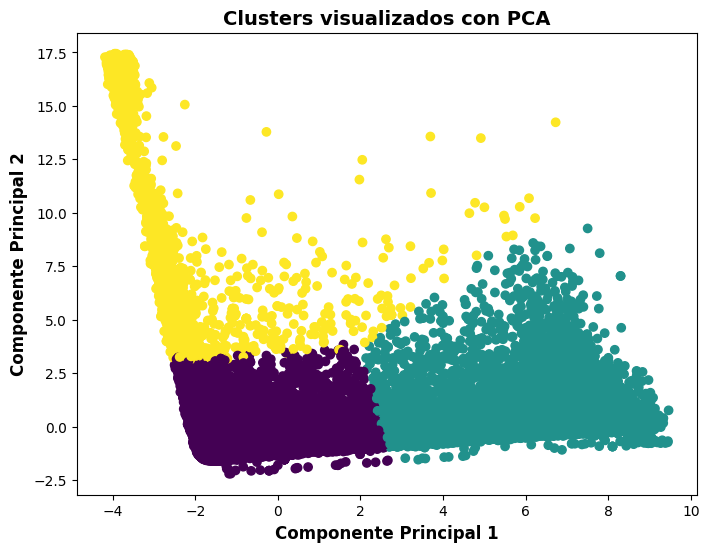

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters,
    cmap="viridis"
)

plt.xlabel("Componente Principal 1", fontsize=12, fontweight="bold")
plt.ylabel("Componente Principal 2", fontsize=12, fontweight="bold")
plt.title("Clusters visualizados con PCA", fontsize=14, fontweight="bold")

plt.show()

Con una varianza explicada del 80% con 2 componentes, se puede observar que la segmentación realizada genera 3 clusters con bajo solapamiento, estando dentro de los estándares de la industria.

##Caracterización de los clusters y recomendaciones

Para la caracterización se vuelven a incluir las variables categóricas que fueron excluidas previamente, con el fin de facilitar la interpretación de la segmentación.

In [ ]:
#Depuración de registros nulos y filas redundantes
df_clusters = df.dropna(subset=['track_id', 'artists', 'track_name', 'popularity']).copy()
#Resolución de duplicados a nivel de track único
df_clusters = df_clusters.groupby('track_id', as_index=False).first()
df_clusters['cluster'] = df_clean['cluster']
df_clusters['artista_principal'] = df_clusters['artists'].astype(str).str.split(';').str[0].str.strip()
df_clusters['es_colaboracion'] = df_clusters['artists'].astype(str).str.contains(';').astype(int)

In [ ]:
#Función para obtener la categoría más frecuente
def moda_segura(serie):
    moda = serie.mode(dropna=True)
    return moda.iloc[0] if not moda.empty else None
#Género más frecuente en cada cluster
genero_principal = (
    df_clusters.groupby("cluster")["track_genre"]
    .agg(moda_segura)
    .rename("genero_principal")
)
#Porcentaje de canciones explícitas
porcentaje_explicitas = (
    df_clusters.groupby("cluster")["explicit"]
    .mean()
    .mul(100)
    .round(1)
    .rename("explicit_%")
)
# Número de canciones por cluster
cantidad = (
    df_clusters.groupby("cluster")
    .size()
    .rename("n_canciones")
)
#Mediana de la popularidad por cluster
mediana_popularity = (
    df_clusters.groupby("cluster")["popularity"]
    .median()
    .round(1)
    .rename("popularity_mediana")
)
#Unir todos los resúmenes
tabla_clusters = pd.concat(
    [
        cantidad,
        genero_principal,
        porcentaje_explicitas,
        mediana_popularity
    ],
    axis=1
)

display(tabla_clusters)

,n_canciones,genero_principal,explicit_%,popularity_mediana
cluster,,,,
0,67030,forro,7.8,36.0
1,17460,study,2.5,24.0
2,5250,comedy,39.0,27.0


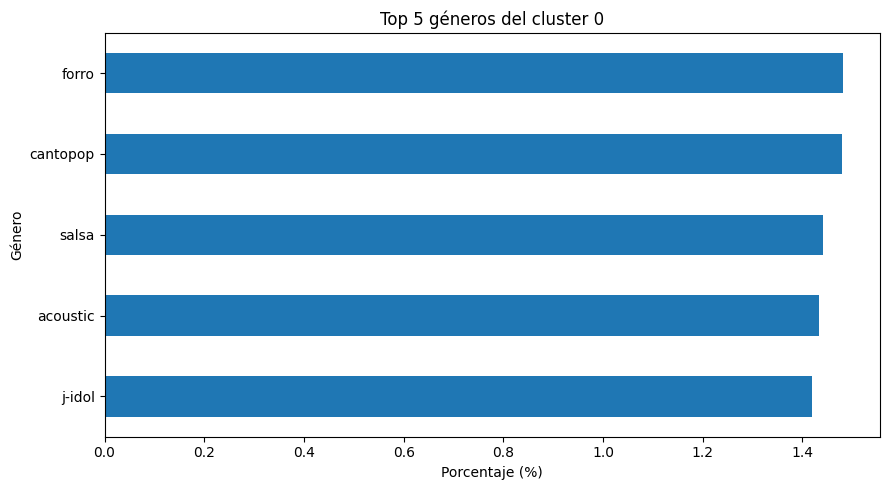

In [ ]:
#Géneros más representativos del cluster 0
generos = (
    df_clusters.loc[
        df_clusters["cluster"] == 0,
        "track_genre"
    ]
    .value_counts(normalize=True)
    .mul(100)
    .head(5)
    .sort_values()
)

generos.plot(kind="barh", figsize=(9, 5))

plt.title(f"Top {5} géneros del cluster {0}")
plt.xlabel("Porcentaje (%)")
plt.ylabel("Género")
plt.tight_layout()
plt.show()

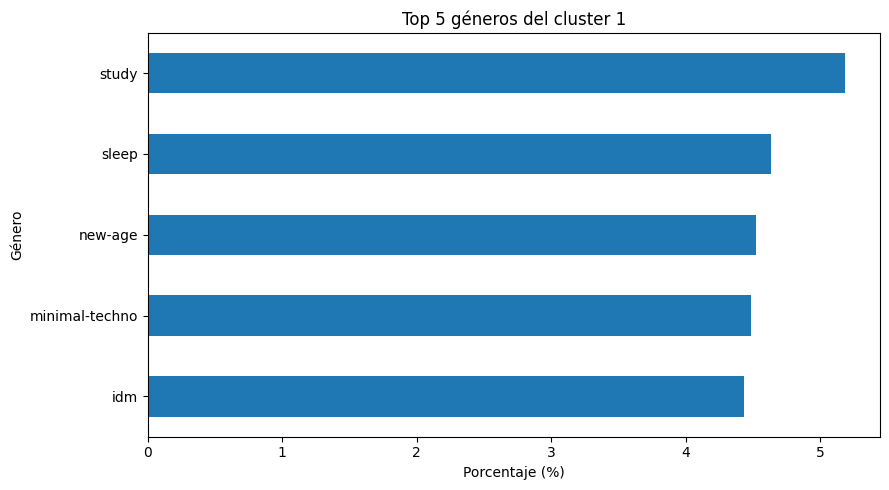

In [ ]:
#Géneros más representativos del cluster 1
generos = (
    df_clusters.loc[
        df_clusters["cluster"] == 1,
        "track_genre"
    ]
    .value_counts(normalize=True)
    .mul(100)
    .head(5)
    .sort_values()
)

generos.plot(kind="barh", figsize=(9, 5))

plt.title(f"Top {5} géneros del cluster {1}")
plt.xlabel("Porcentaje (%)")
plt.ylabel("Género")
plt.tight_layout()
plt.show()

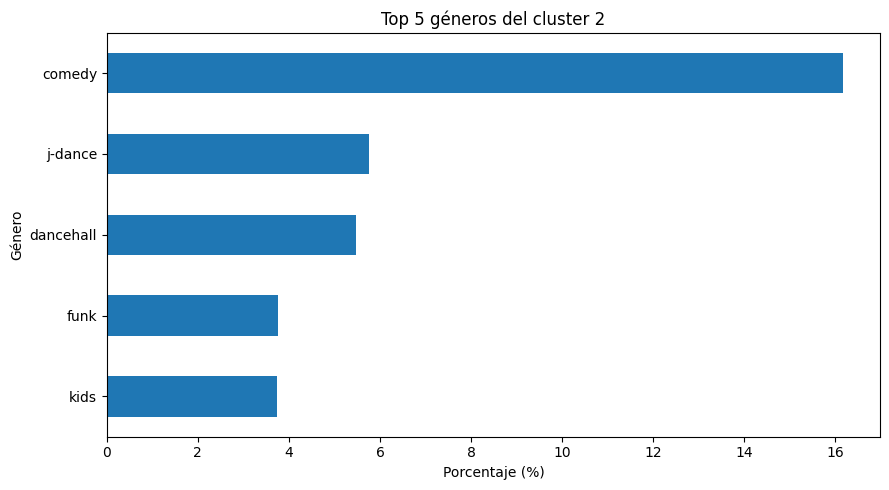

In [ ]:
#Géneros más representativos del cluster 2
generos = (
    df_clusters.loc[
        df_clusters["cluster"] == 2,
        "track_genre"
    ]
    .value_counts(normalize=True)
    .mul(100)
    .head(5)
    .sort_values()
)

generos.plot(kind="barh", figsize=(9, 5))

plt.title(f"Top {5} géneros del cluster {2}")
plt.xlabel("Porcentaje (%)")
plt.ylabel("Género")
plt.tight_layout()
plt.show()

In [ ]:
#Diversificación de los clusters
for cluster in range(3):
  total_generos = df_clusters.loc[
      df_clusters["cluster"] == cluster,
      "track_genre"
  ].nunique()

  print(f"Cantidad total de géneros en el cluster {cluster}: {total_generos}")

Cantidad total de géneros en el cluster 0: 113
Cantidad total de géneros en el cluster 1: 104
Cantidad total de géneros en el cluster 2: 111


* Cluster 0 (El núcleo de la plataforma): Concentra aproximadamente el 75% del total de canciones. Al ser el grupo mayoritario, presenta la mayor variedad de géneros (113 géneros únicos) y los niveles más altos de popularidad mediana, consolidándose como la columna vertebral del catálogo. Dado que alberga la mayor variedad de géneros y canciones populares, este cluster debe ser la "puerta de entrada" para nuevos usuarios. Este es el lugar natural para ubicar lanzamientos masivos, promociones de artistas consolidados y campañas publicitarias generales.

* Cluster 1 (Nicho de relajación y escucha activa): Muestra una marcada especialización con una baja diversificación (solo 104 géneros únicos). Sus canciones están fuertemente orientadas a contextos de bienestar, calma y concentración. Se pueden diseñar y promocionar playlists temáticas basadas en momentos del día o actividades.

* Cluster 2 (Nicho de alta energía): Es el segmento más exclusivo o minoritario del dataset (5.9% del total), enfocado principalmente en ritmos de baile, optimismo y notas alegres, alejándose del promedio general de la plataforma. Aunque sea el segmento más pequeño, crear playlists para entrenamiento, fiestas o fin de semana puede generar altos niveles de retención, debido a la pasionalidad que se asocia al tipo de música.

In [ ]:
URL_BASE = "https://raw.githubusercontent.com/Mapabaoy12/EntregaMachineLearning3/main/data"
def cargar(nombre, **kw):
    try:
        return pd.read_csv(f"{URL_BASE}/{nombre}", **kw)      # 1) desde GitHub
    except Exception:
        try:
            return pd.read_csv(f"data/{nombre}", **kw)        # 2) copia local, si existe
        except FileNotFoundError:
            from google.colab import files                    # 3) subida manual como último recurso
            print(f"Sube {nombre}"); files.upload()
            return pd.read_csv(nombre, **kw)

imp = cargar("importancias_modelos.csv", index_col=0)
res = cargar("predicciones_test.csv")

df_clusters["explicit"] = df_clusters["explicit"].astype(int)
cols_audio = cols_num
imp.head(10)


,Random Forest,LightGBM,XGBoost
artista_principal,0.661216,0.651540,0.635946
track_genre,0.144727,0.151144,0.151046
loudness,0.007905,0.006786,0.006825
duration_s,0.007215,0.006193,0.006253
energy,0.008213,0.004915,0.004799
instrumentalness,0.007636,0.004960,0.004747
acousticness,0.005791,0.004354,0.003954
danceability,0.005099,0.002582,0.003488
speechiness,0.002947,0.001955,0.003280
liveness,0.002248,0.002724,0.002197


#Perfiles estandarizados de cada cluster

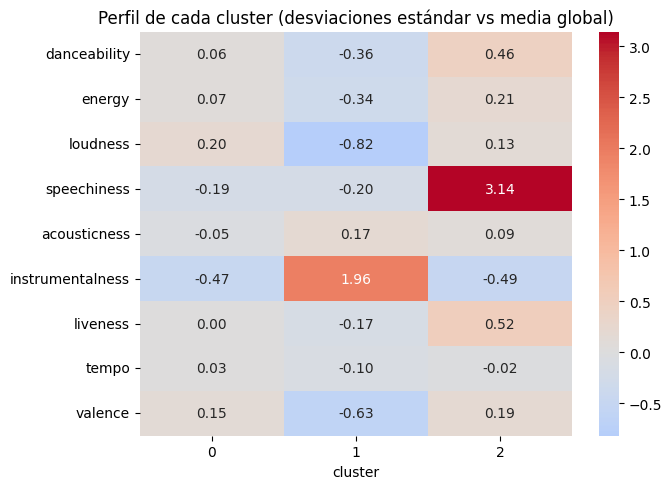

In [ ]:
z = (df_clusters[cols_audio] - df_clusters[cols_audio].mean()) / df_clusters[cols_audio].std()
perfil_z = z.groupby(df_clusters["cluster"]).mean()

plt.figure(figsize=(7, 5))
sns.heatmap(perfil_z.T, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de cada cluster (desviaciones estándar vs media global)")
plt.tight_layout(); plt.show()

Cluster 0 (75%)\
Qué lo distingue: Todo cerca de 0; solo instrumentalidad −0,47 y volumen +0,20\
Perfil: canciones con voz, el “promedio” del catálogo

Cluster 1 (19.5%)\
Qué lo distingue: Instrumentalidad +1,96, volumen −0,82, valencia −0,63, danceability −0,36, energía −0,34\
Perfil:música sin voz, más suave, baja y menos alegre

Cluster 0 (5.9%)\
Qué lo distingue: Speechiness +3,14, liveness +0,52, danceability +0,46\
Perfil:mucha palabra hablada, como comedia, y sonido de directo


#Importancia en los modelos de las variables que separan los clusters

,eta2_cluster,Random Forest,LightGBM,XGBoost
instrumentalness,0.9297,0.0076,0.0050,0.0047
speechiness,0.6129,0.0029,0.0020,0.0033
loudness,0.1625,0.0079,0.0068,0.0068
valence,0.0966,0.0019,0.0019,0.0016
danceability,0.0408,0.0051,0.0026,0.0035
energy,0.0288,0.0082,0.0049,0.0048
liveness,0.0211,0.0022,0.0027,0.0022
acousticness,0.0083,0.0058,0.0044,0.0040
tempo,0.0028,0.0013,0.0015,0.0014


Correlación de Spearman entre ranking de separación y ranking de importancia:
Random Forest    0.35
LightGBM         0.37
XGBoost          0.40
Name: eta2_cluster, dtype: float64


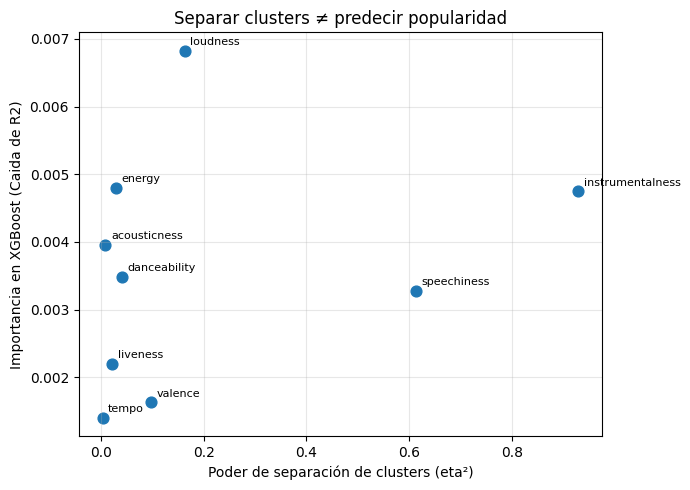

In [ ]:
#mide la fraccion de la varianza de cada variable explicada por el cluster
# si da 0 no separa, si da 1 separa perfecto
def eta2(x, g):
    """
    Calcula el eta cuadrado (eta²) ajustado, midiendo qué fracción
    de la varianza de 'x' es explicada por los grupos 'g'.
    """
    k = g.nunique()
    n = len(x)

    # Prevenir divisiones por cero si los datos son inválidos
    if n <= k:
        return 0.0

    # 1. Suma de Cuadrados Total (Varianza general de la variable)
    ss_total = ((x - x.mean()) ** 2).sum()

    if ss_total == 0:
        return 0.0

    # 2. Suma de Cuadrados Intra-grupo (Varianza no explicada por el cluster)
    group_means = x.groupby(g).transform('mean')
    ss_within = ((x - group_means) ** 2).sum()

    # 3. Calcular eta2 base (e)
    e = 1 - (ss_within / ss_total)

    # 4. Aplicar el ajuste por grados de libertad
    eta2_ajustado = 1 - (1 - e) * (n - 1) / (n - k)

    # Asegurar que el valor no baje de 0 por efecto del ajuste
    return max(0.0, eta2_ajustado)

sep = pd.Series({c: eta2(df_clusters[c], df_clusters["cluster"]) for c in cols_audio}, name="eta2_cluster")
comp = pd.concat([sep, imp.reindex(cols_audio)], axis=1).dropna()
display(comp.round(4).sort_values("eta2_cluster", ascending=False))
print("Correlación de Spearman entre ranking de separación y ranking de importancia:")
print(comp.corr(method="spearman")["eta2_cluster"].drop("eta2_cluster").round(2))

plt.figure(figsize=(7, 5))
plt.scatter(comp["eta2_cluster"], comp["XGBoost"], s=60)
for v, r in comp.iterrows(): plt.annotate(v, (r["eta2_cluster"], r["XGBoost"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.xlabel("Poder de separación de clusters (eta²)"); plt.ylabel("Importancia en XGBoost (Caida de R2)")
plt.title("Separar clusters ≠ predecir popularidad"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

Los clusters se definen por instrumentalness y speechiness, pero la importancia de esas variables en los modelos es baja. La correlación de Spearman entre el ranking de separación y el de importancia es de 0,35-0,40 (solo 9 variables, por lo que es un indicador descriptivo, no una prueba). Conclusión: segmentar por sonido no es lo mismo que predecir éxito; los clusters sirven para curar y recomendar por similitud, no para estimar popularidad. Lo que predice popularidad son el artista y el género.

#Éxito y popularidad por cluster

,n,pop_media,pop_mediana,pct_top20,pct_pop_cero,pct_explicit,pct_colab,lift_top20
cluster,,,,,,,,
0,67030,34.6,36.0,23.1,11.6,7.8,25.3,1.10
1,17460,28.1,24.0,13.4,7.6,2.5,22.3,0.64
2,5250,32.2,27.0,17.6,7.0,39.0,32.4,0.84


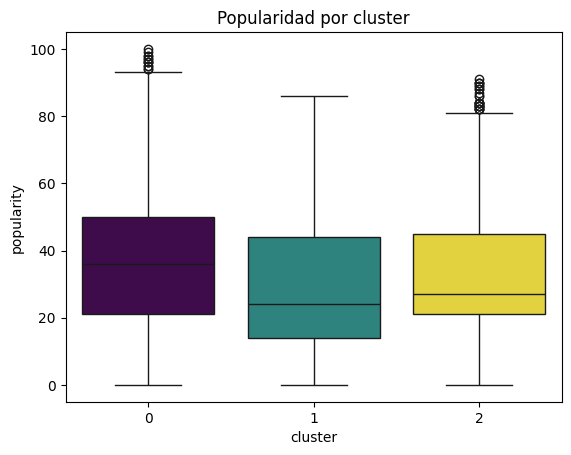

In [ ]:
umbral = df_clusters["popularity"].quantile(0.80)          # "éxito" = top 20% de popularidad
df_clusters["top20"] = (df_clusters["popularity"] >= umbral).astype(int)
base = df_clusters["top20"].mean() * 100

tabla_exito = df_clusters.groupby("cluster").agg(
    n=("track_id", "count"),
    pop_media=("popularity", "mean"),
    pop_mediana=("popularity", "median"),
    pct_top20=("top20", lambda s: s.mean() * 100),
    pct_pop_cero=("popularity", lambda s: (s == 0).mean() * 100),
    pct_explicit=("explicit", lambda s: s.mean() * 100),
    pct_colab=("es_colaboracion", lambda s: s.mean() * 100),
).round(1)
tabla_exito["lift_top20"] = (tabla_exito["pct_top20"] / base).round(2)   # >1: más éxito que el promedio
display(tabla_exito)

sns.boxplot(data=df_clusters, x="cluster", y="popularity", palette="viridis", hue="cluster", legend=False)
plt.title("Popularidad por cluster"); plt.show()

El cluster 0 concentra más éxitos, pero también más canciones con popularidad 0: es el segmento más polarizado. El cluster instrumental tiene un lift de 0,64 (menos probabilidad de éxito masivo).

#Peso de artista y género dentro de cada cluster

In [ ]:
filas = []
for c, g in df_clusters.groupby("cluster"):
    vc_art = g["artista_principal"].value_counts(normalize=True)
    vc_gen = g["track_genre"].value_counts(normalize=True)
    filas.append({
        "cluster": c,
        "artistas_unicos": g["artista_principal"].nunique(),
        "canciones_por_artista": len(g) / g["artista_principal"].nunique(),
        "%_top10_artistas": vc_art.head(10).sum() * 100,
        "HHI_genero": (vc_gen ** 2).sum(),                              # concentración de géneros
        "eta2_pop~genero": eta2(g["popularity"], g["track_genre"]),     # cuánto explica el género
        "eta2_pop~artista": eta2(g["popularity"], g["artista_principal"]),
    })
pd.DataFrame(filas).set_index("cluster").round(3)

,artistas_unicos,canciones_por_artista,%_top10_artistas,HHI_genero,eta2_pop~genero,eta2_pop~artista
cluster,,,,,,
0,14166,4.732,2.911,0.010,0.294,0.581
1,5005,3.489,5.762,0.028,0.465,0.697
2,2268,2.315,6.895,0.044,0.379,0.680


El género explica más la popularidad en el cluster instrumental (η² = 0,47). Los η² por artista están inflados por la alta cardinalidad (pocas canciones por artista), sobre todo en el cluster 2; deben ajustarse antes de compararse.

#clusters en donde falla mas el modelo

MAE por cluster (test):


,pred_rl,pred_rf,pred_lgbm,pred_xgb,n_test
cluster,,,,,
0,9.64,8.85,8.97,9.07,13466
1,7.95,7.28,7.41,7.47,3426
2,7.33,6.80,6.83,6.94,1056


Sesgo medio (predicho − real): >0 sobreestima, <0 subestima


,pred_rl,pred_rf,pred_lgbm,pred_xgb
cluster,,,,
0,0.07,-0.07,-0.04,-0.03
1,-0.24,-0.08,-0.20,-0.25
2,0.93,0.91,0.71,0.69


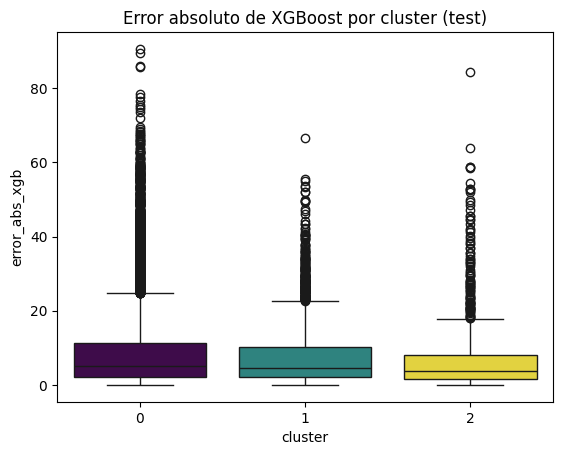

In [ ]:
r = res.merge(df_clusters[["track_id", "cluster"]], on="track_id", how="inner")
modelos_pred = ["pred_rl", "pred_rf", "pred_lgbm", "pred_xgb"]

mae = pd.DataFrame({m: (r["popularity"] - r[m]).abs().groupby(r["cluster"]).mean() for m in modelos_pred}).round(2)
sesgo = pd.DataFrame({m: (r[m] - r["popularity"]).groupby(r["cluster"]).mean() for m in modelos_pred}).round(2)
mae["n_test"] = r.groupby("cluster").size()
print("MAE por cluster (test):"); display(mae)
print("Sesgo medio (predicho − real): >0 sobreestima, <0 subestima"); display(sesgo)

r["error_abs_xgb"] = (r["popularity"] - r["pred_xgb"]).abs()
sns.boxplot(data=r, x="cluster", y="error_abs_xgb", palette="viridis", hue="cluster", legend=False)
plt.title("Error absoluto de XGBoost por cluster (test)"); plt.show()

El error es mayor en el cluster 0 y menor en los otros; sin embargo, la menor popularidad y dispersión de los clusters 1 y 2 puede explicar parte de ello (se recomienda comparar el MAE con la desviación estándar de la popularidad de cada cluster).

Los ensambles mejoran sobre el modelo lineal en los tres clusters (la mayor ganancia, de ≈ 0,8 puntos, ocurre en el cluster 0).

Sesgo medio (predicho − real): ≈ 0 en los clusters 0 y 1; +0,7 a +0,9 en el cluster 2 (el modelo sobreestim levemente la popularidad del contenido hablado).

#Cambio de los factores de éxito entre clusters

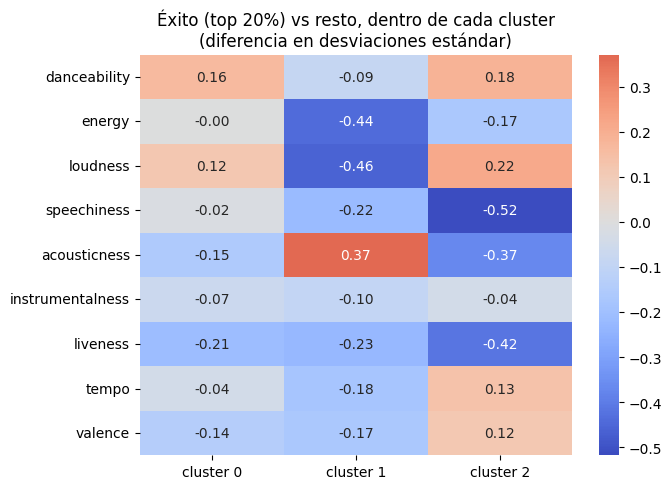

In [ ]:
dif = {}
for c, g in df_clusters.groupby("cluster"):
    hit = g["top20"] == 1
    dif[f"cluster {c}"] = (g.loc[hit, cols_audio].mean() - g.loc[~hit, cols_audio].mean()) / g[cols_audio].std()
dif = pd.DataFrame(dif)

plt.figure(figsize=(7, 5))
sns.heatmap(dif, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Éxito (top 20%) vs resto, dentro de cada cluster\n(diferencia en desviaciones estándar)")
plt.tight_layout(); plt.show()

Dentro del cluster instrumental, el éxito se asocia con música más acústica, suave y de menor volumen, lo opuesto a lo que ocurre en los otros dos clusters (donde más volumen se asocia con éxito). Es decir, el "sonido del éxito" depende del segmento, y un modelo global promedia efectos contrarios.